<a href="https://colab.research.google.com/github/starsyntaxx/MarketIQ/blob/main/notebooks/02_exploratory_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
import os

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

In [3]:
def extract_file_from_drive(zip_path, file_name, extract_to='/content/extracted'):

    os.makedirs(extract_to, exist_ok=True)

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:

        if file_name not in zip_ref.namelist():
            raise FileNotFoundError(
                f"{file_name} not found in the ZIP archive."
            )

        zip_ref.extract(file_name, extract_to)

    extracted_path = os.path.join(extract_to, file_name)

    return extracted_path

In [4]:
pd.reset_option('display.max_columns')
pd.reset_option('display.max_rows')

In [5]:
zip_path = "/content/drive/MyDrive/ML PROJECTS/MarketIQ/data/raw/NGA_2025_HFCP_v01_M_CSV.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print(zip_ref.namelist())

['Raw_data_spatialrev.csv', 'level2_price_yellow_maize.csv', 'level2_price_yam.csv', 'level2_price_white_maize.csv', 'level2_price_white_beans.csv', 'level2_price_soybean.csv', 'level2_price_sorghum.csv', 'level2_price_local_rice.csv', 'level2_price_imported_rice.csv', 'level2_price_garri.csv', 'level2_price_brown_beans.csv']


In [6]:
csv_files = [
    'Raw_data_spatialrev.csv',
    'level2_price_yellow_maize.csv',
    'level2_price_yam.csv',
    'level2_price_white_maize.csv',
    'level2_price_white_beans.csv',
    'level2_price_soybean.csv',
    'level2_price_sorghum.csv',
    'level2_price_local_rice.csv',
    'level2_price_imported_rice.csv',
    'level2_price_garri.csv',
    'level2_price_brown_beans.csv'
]

dataframes = {}

for i, file_name in enumerate(csv_files, start=1):
    try:
        extracted_path = extract_file_from_drive(zip_path, file_name)
        df_name = f'df_{i}'
        globals()[df_name] = pd.read_csv(extracted_path)
        dataframes[df_name] = file_name
        print(f"Successfully loaded '{file_name}' into variable `{df_name}` (Shape: {globals()[df_name].shape})")
    except Exception as e:
        print(f"Failed to load {file_name}: {e}")

Successfully loaded 'Raw_data_spatialrev.csv' into variable `df_1` (Shape: (220214, 72))
Successfully loaded 'level2_price_yellow_maize.csv' into variable `df_2` (Shape: (190873, 25))
Successfully loaded 'level2_price_yam.csv' into variable `df_3` (Shape: (173180, 25))
Successfully loaded 'level2_price_white_maize.csv' into variable `df_4` (Shape: (199828, 25))
Successfully loaded 'level2_price_white_beans.csv' into variable `df_5` (Shape: (202059, 25))
Successfully loaded 'level2_price_soybean.csv' into variable `df_6` (Shape: (186293, 25))
Successfully loaded 'level2_price_sorghum.csv' into variable `df_7` (Shape: (185067, 25))
Successfully loaded 'level2_price_local_rice.csv' into variable `df_8` (Shape: (198630, 25))
Successfully loaded 'level2_price_imported_rice.csv' into variable `df_9` (Shape: (141612, 25))
Successfully loaded 'level2_price_garri.csv' into variable `df_10` (Shape: (202731, 25))
Successfully loaded 'level2_price_brown_beans.csv' into variable `df_11` (Shape: (17

In [7]:
print("Available DataFrame variables:")
for key, val in dataframes.items():
    print(f"{key}: {val}")

Available DataFrame variables:
df_1: Raw_data_spatialrev.csv
df_2: level2_price_yellow_maize.csv
df_3: level2_price_yam.csv
df_4: level2_price_white_maize.csv
df_5: level2_price_white_beans.csv
df_6: level2_price_soybean.csv
df_7: level2_price_sorghum.csv
df_8: level2_price_local_rice.csv
df_9: level2_price_imported_rice.csv
df_10: level2_price_garri.csv
df_11: level2_price_brown_beans.csv


### Baseline Analysis of `df_1` (Raw_data_spatialrev.csv)

In [8]:
# 1. General Overview of the dataset
print("=== Dataset Shape ===")
print(df_1.shape)

print("\n=== Info ===")
display(df_1.info(max_cols=100))

=== Dataset Shape ===
(220214, 72)

=== Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220214 entries, 0 to 220213
Data columns (total 72 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   fid           220214 non-null  int64  
 1   submissio     220214 non-null  int64  
 2   date          220214 non-null  object 
 3   zonecode1     220214 non-null  int64  
 4   geopol_zon    220214 non-null  object 
 5   statecode1    220214 non-null  int64  
 6   zonelabel1    220214 non-null  object 
 7   statelabel    220214 non-null  object 
 8   lga           220214 non-null  int64  
 9   lgalabel      220214 non-null  object 
 10  sector        220214 non-null  object 
 11  vc_id         220214 non-null  object 
 12  staff_vali    220214 non-null  int64  
 13  consent       220214 non-null  int64  
 14  market_typ    220214 non-null  object 
 15  price_cate    220214 non-null  object 
 16  market_tim    220214 non-null  int64  
 17 

None

In [9]:
# 2. Display the first few rows to examine data structure
display(df_1.head().T)

,0,1,2,3,4
fid,0,1,2,3,4
submissio,4316,5346,5541,5680,5690
date,12/1/2024,12/1/2024,12/2/2024,12/2/2024,12/2/2024
zonecode1,1,1,3,1,1
geopol_zon,nbsnorthcentral,nbsnorthcentral,nbsnorthwest,nbsnorthcentral,nbsnorthcentral
...,...,...,...,...,...
gps_coords,9.0266823 7.607355399999999 0.0 0.0,9.0266823 7.607355399999999 0.0 0.0,10.4607247 7.4472635 630.2872318788975 0.0,7.1928081 8.146351333333333 218.474 0.0,7.192811033333333 8.14631625 222.09 0.0
gps_latitu,9.026682,9.026682,10.460725,7.192808,7.192811
gps_longit,7.607355,7.607355,7.447264,8.146351,8.146316
gps_precis,NaN,NaN,NaN,NaN,NaN


In [10]:
# 3. Missing Value Analysis
missing_values = df_1.isnull().sum()
missing_percentage = (df_1.isnull().sum() / len(df_1)) * 100
missing_df = pd.DataFrame({'Missing Values': missing_values, 'Percentage (%)': missing_percentage})
missing_df = missing_df[missing_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)

print("=== Columns with Missing Values ===")
if not missing_df.empty:
    display(missing_df)
else:
    print("No missing values found!")

=== Columns with Missing Values ===


,Missing Values,Percentage (%)
uom_import,63945,29.037663
q_rice,63945,29.037663
price_impo,63945,29.037663
price_impo_1,63945,29.037663
q_yam,36714,16.671965
uom_yam,36714,16.671965
price_yam_,36714,16.671965
price_yam,36714,16.671965
q_brownbea,28999,13.168554
price_br_1,28999,13.168554


In [11]:
# 4. Summary Statistics for numerical and categorical variables
print("=== Summary Statistics (Numerical) ===")
display(df_1.describe())

print("\n=== Summary Statistics (Categorical) ===")
display(df_1.describe(include=['object', 'category']))

=== Summary Statistics (Numerical) ===


,fid,submissio,zonecode1,statecode1,lga,staff_vali,consent,market_tim,uom_ymaize,q_ymaize,...,price_yam,price_yam_,uom_soyabe,q_soyabean,price_soya,price_so_2,gps_latitu,gps_longit,gps_precis,count
count,220214.000000,220214.000000,220214.000000,220214.000000,220214.000000,220214.000000,220214.000000,2.202140e+05,203418.000000,203418.00000,...,1.835000e+05,1.835000e+05,199310.000000,199310.000000,1.993100e+05,1.993100e+05,220214.000000,220214.000000,219218.000000,220214.0
mean,110106.500000,113258.710177,3.471292,19.347312,1946.054025,0.109984,0.999755,5.980224e+03,6.091645,1.05239,...,3.395627e+03,1.885100e+03,5.628720,1.048367,1.269427e+04,5.744930e+03,8.529373,7.287308,93.935890,1.0
std,63570.450427,63699.305641,1.758067,10.325774,1031.751518,0.312870,0.015657,1.842417e+06,20.959550,0.42878,...,1.899352e+05,1.899225e+05,19.809292,0.395232,1.881595e+06,1.334927e+06,2.514299,2.430840,453.606456,0.0
min,0.000000,189.000000,1.000000,1.000000,101.000000,0.000000,0.000000,-8.500000e+01,0.160000,1.00000,...,1.000000e+02,7.142857e+00,0.200000,1.000000,1.000000e+02,1.050000e+00,4.426009,2.714769,1.000000,1.0
25%,55053.250000,58209.250000,2.000000,10.000000,1019.000000,0.000000,1.000000,1.000000e+01,0.670000,1.00000,...,1.700000e+03,8.571429e+02,0.650000,1.000000,1.100000e+03,1.125000e+03,6.456500,5.264294,4.000000,1.0
50%,110106.500000,113306.500000,3.000000,19.000000,1944.000000,0.000000,1.000000,2.000000e+01,1.300000,1.00000,...,2.400000e+03,1.142857e+03,1.400000,1.000000,1.800000e+03,1.428571e+03,7.843022,7.336395,5.000000,1.0
75%,165159.750000,168395.750000,5.000000,28.000000,2806.000000,0.000000,1.000000,4.000000e+01,1.300000,1.00000,...,3.200000e+03,1.714286e+03,1.400000,1.000000,2.500000e+03,1.857143e+03,10.488568,8.529103,5.000000,1.0
max,220213.000000,223519.000000,6.000000,37.000000,3706.000000,1.000000,1.000000,6.584807e+08,100.000000,9.00000,...,8.135568e+07,8.135568e+07,100.000000,9.000000,8.033116e+08,5.737940e+08,13.754103,14.209325,6114.000000,1.0



=== Summary Statistics (Categorical) ===


,date,geopol_zon,zonelabel1,statelabel,lgalabel,sector,vc_id,market_typ,price_cate,maize_yell,maize_whit,sorghum,imported_r,local_rice,brown_bean,white_bean,garri_conf,yam_confir,soyabeans,gps_coords
count,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214,220214
unique,217,6,6,37,591,2,901,10,4,3,3,3,3,3,3,3,3,3,3,214904
top,11/29/2024,nbsnorthwest,North West,KANO,AKURE SOUTH,Urban,BORNO2,RoadSide_shops_street vendors,Retail,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4.6880963 6.3161275 0.0 1700.0
freq,1452,45613,45923,9907,3945,151148,1039,67792,193398,203418,212848,206507,156269,211810,191215,217900,212002,183500,199310,72


### Visualizing Standardized Commodity Prices in `df_1`

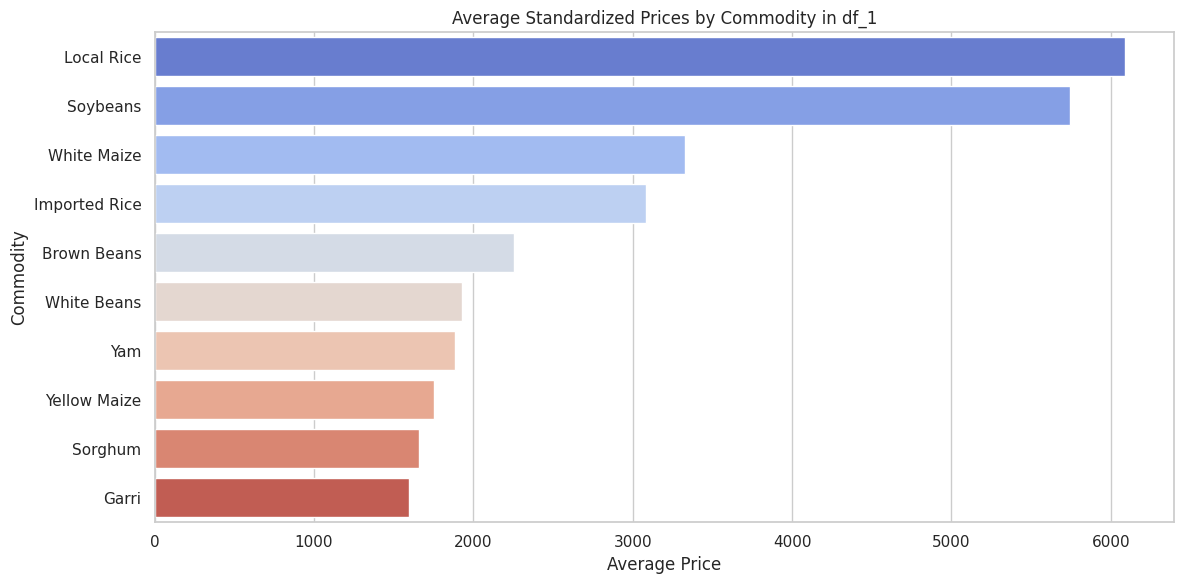

In [12]:
# Identify the standardized price columns (typically ending in _1 or _2 in df_1)
price_cols = {
    'Yellow Maize': 'price_ym_1',
    'White Maize': 'price_wm_1',
    'Sorghum': 'price_so_1',
    'Imported Rice': 'price_impo_1',
    'Local Rice': 'price_lo_1',
    'Brown Beans': 'price_br_1',
    'White Beans': 'price_wh_1',
    'Garri': 'price_ga_1',
    'Yam': 'price_yam_',
    'Soybeans': 'price_so_2'
}

# Calculate mean prices for each commodity (ignoring missing values)
mean_prices = {commodity: df_1[col].mean() for commodity, col in price_cols.items()}
mean_prices_df = pd.DataFrame(list(mean_prices.items()), columns=['Commodity', 'Average Standardized Price']).sort_values(by='Average Standardized Price', ascending=False)

# Plot the average prices
plt.figure(figsize=(12, 6))
sns.barplot(data=mean_prices_df, x='Average Standardized Price', y='Commodity', palette='coolwarm', hue='Commodity', legend=False)
plt.title('Average Standardized Prices by Commodity in df_1')
plt.xlabel('Average Price')
plt.ylabel('Commodity')
plt.tight_layout()
plt.show()

### Average Price of Each Commodity by Geopolitical Zone (Community)

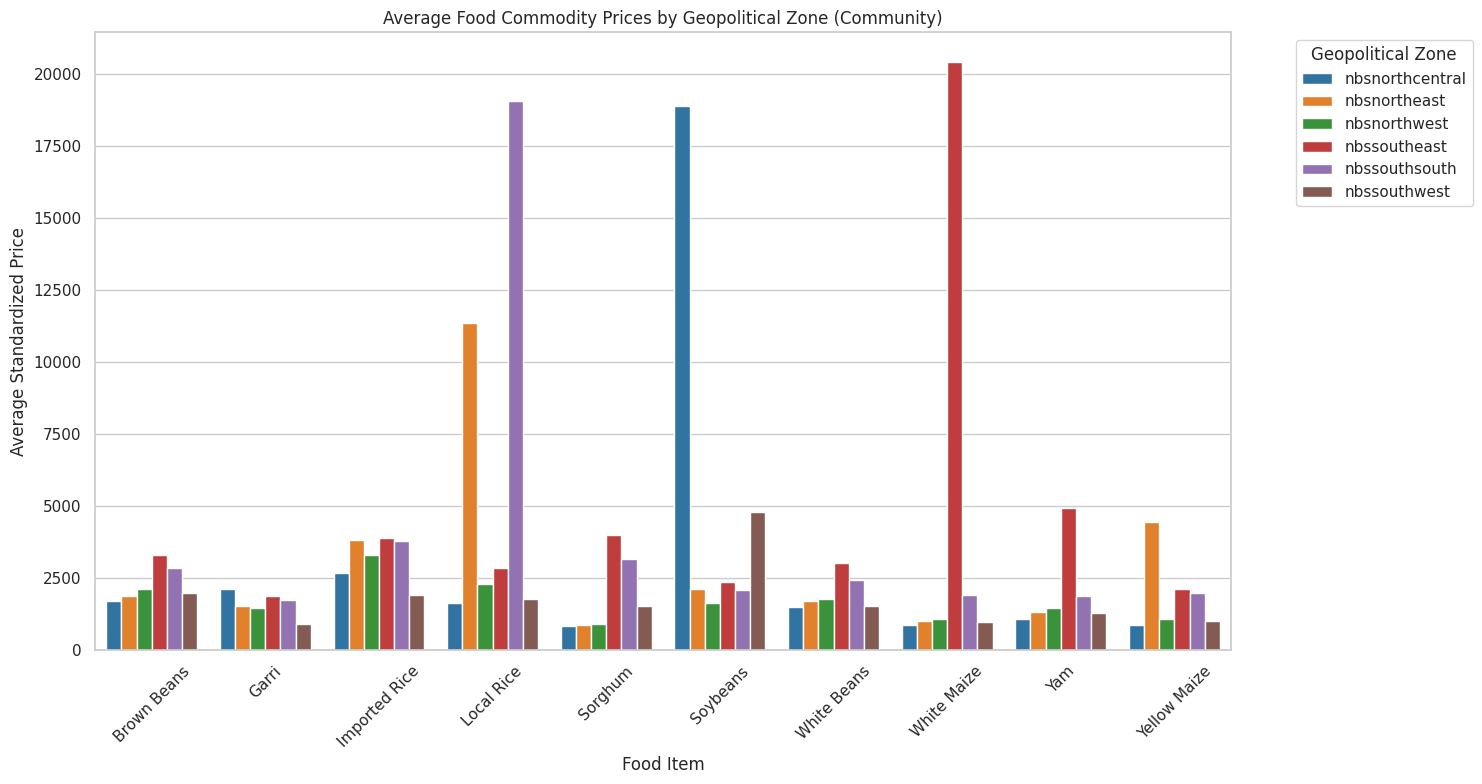

In [13]:
# Map columns to food items
price_cols = {
    'Yellow Maize': 'price_ym_1',
    'White Maize': 'price_wm_1',
    'Sorghum': 'price_so_1',
    'Imported Rice': 'price_impo_1',
    'Local Rice': 'price_lo_1',
    'Brown Beans': 'price_br_1',
    'White Beans': 'price_wh_1',
    'Garri': 'price_ga_1',
    'Yam': 'price_yam_',
    'Soybeans': 'price_so_2'
}

# Create a melted dataframe of prices grouped by geopol_zon
price_data = []
for food, col in price_cols.items():
    if col in df_1.columns:
        temp_df = df_1[['geopol_zon', col]].dropna().copy()
        temp_df.rename(columns={col: 'Price'}, inplace=True)
        temp_df['Food Item'] = food
        price_data.append(temp_df)

prices_by_zone_df = pd.concat(price_data, ignore_index=True)

# Calculate mean values for plotting
grouped_df = prices_by_zone_df.groupby(['geopol_zon', 'Food Item'])['Price'].mean().reset_index()

# Create the visualization
plt.figure(figsize=(15, 8))
sns.barplot(
    data=grouped_df,
    x='Food Item',
    y='Price',
    hue='geopol_zon',
    palette='tab10'
)
plt.title('Average Food Commodity Prices by Geopolitical Zone (Community)')
plt.xlabel('Food Item')
plt.ylabel('Average Standardized Price')
plt.xticks(rotation=45)
plt.legend(title='Geopolitical Zone', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**DATA CLEANING**

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure date is parsed
df_1['date_parsed'] = pd.to_datetime(df_1['date'], errors='coerce')
df_1['year_month'] = df_1['date_parsed'].dt.to_period('M')

# Standardized price columns mapped to commodities
price_cols = {
    'Yellow Maize': 'price_ym_1',
    'White Maize': 'price_wm_1',
    'Sorghum': 'price_so_1',
    'Imported Rice': 'price_impo_1',
    'Local Rice': 'price_lo_1',
    'Brown Beans': 'price_br_1',
    'White Beans': 'price_wh_1',
    'Garri': 'price_ga_1',
    'Yam': 'price_yam_',
    'Soybeans': 'price_so_2'
}

# Calculate the percentage of missing price entries per State and Month for each commodity
scarcity_records = []

for commodity, col in price_cols.items():
    # Group by state and month, calculate percentage of nulls in the price column
    grouped = df_1.groupby(['statelabel', 'year_month'])[col].apply(lambda x: x.isnull().mean() * 100).reset_index()
    grouped.rename(columns={col: 'missing_rate'}, inplace=True)
    grouped['commodity'] = commodity
    scarcity_records.append(grouped)

# Combine everything into one dataset
scarcity_df = pd.concat(scarcity_records, ignore_index=True)
scarcity_df['year_month_str'] = scarcity_df['year_month'].astype(str)

# Let's inspect the scarcity dataframe
display(scarcity_df.head())


,statelabel,year_month,missing_rate,commodity,year_month_str
0,ABIA,2024-11,0.000000,Yellow Maize,2024-11
1,ABIA,2024-12,0.569801,Yellow Maize,2024-12
2,ABIA,2025-01,0.312989,Yellow Maize,2025-01
3,ABIA,2025-02,0.142857,Yellow Maize,2025-02
4,ABIA,2025-03,0.128205,Yellow Maize,2025-03


/tmp/ipykernel_457/677042648.py:63: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_457/677042648.py:63: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


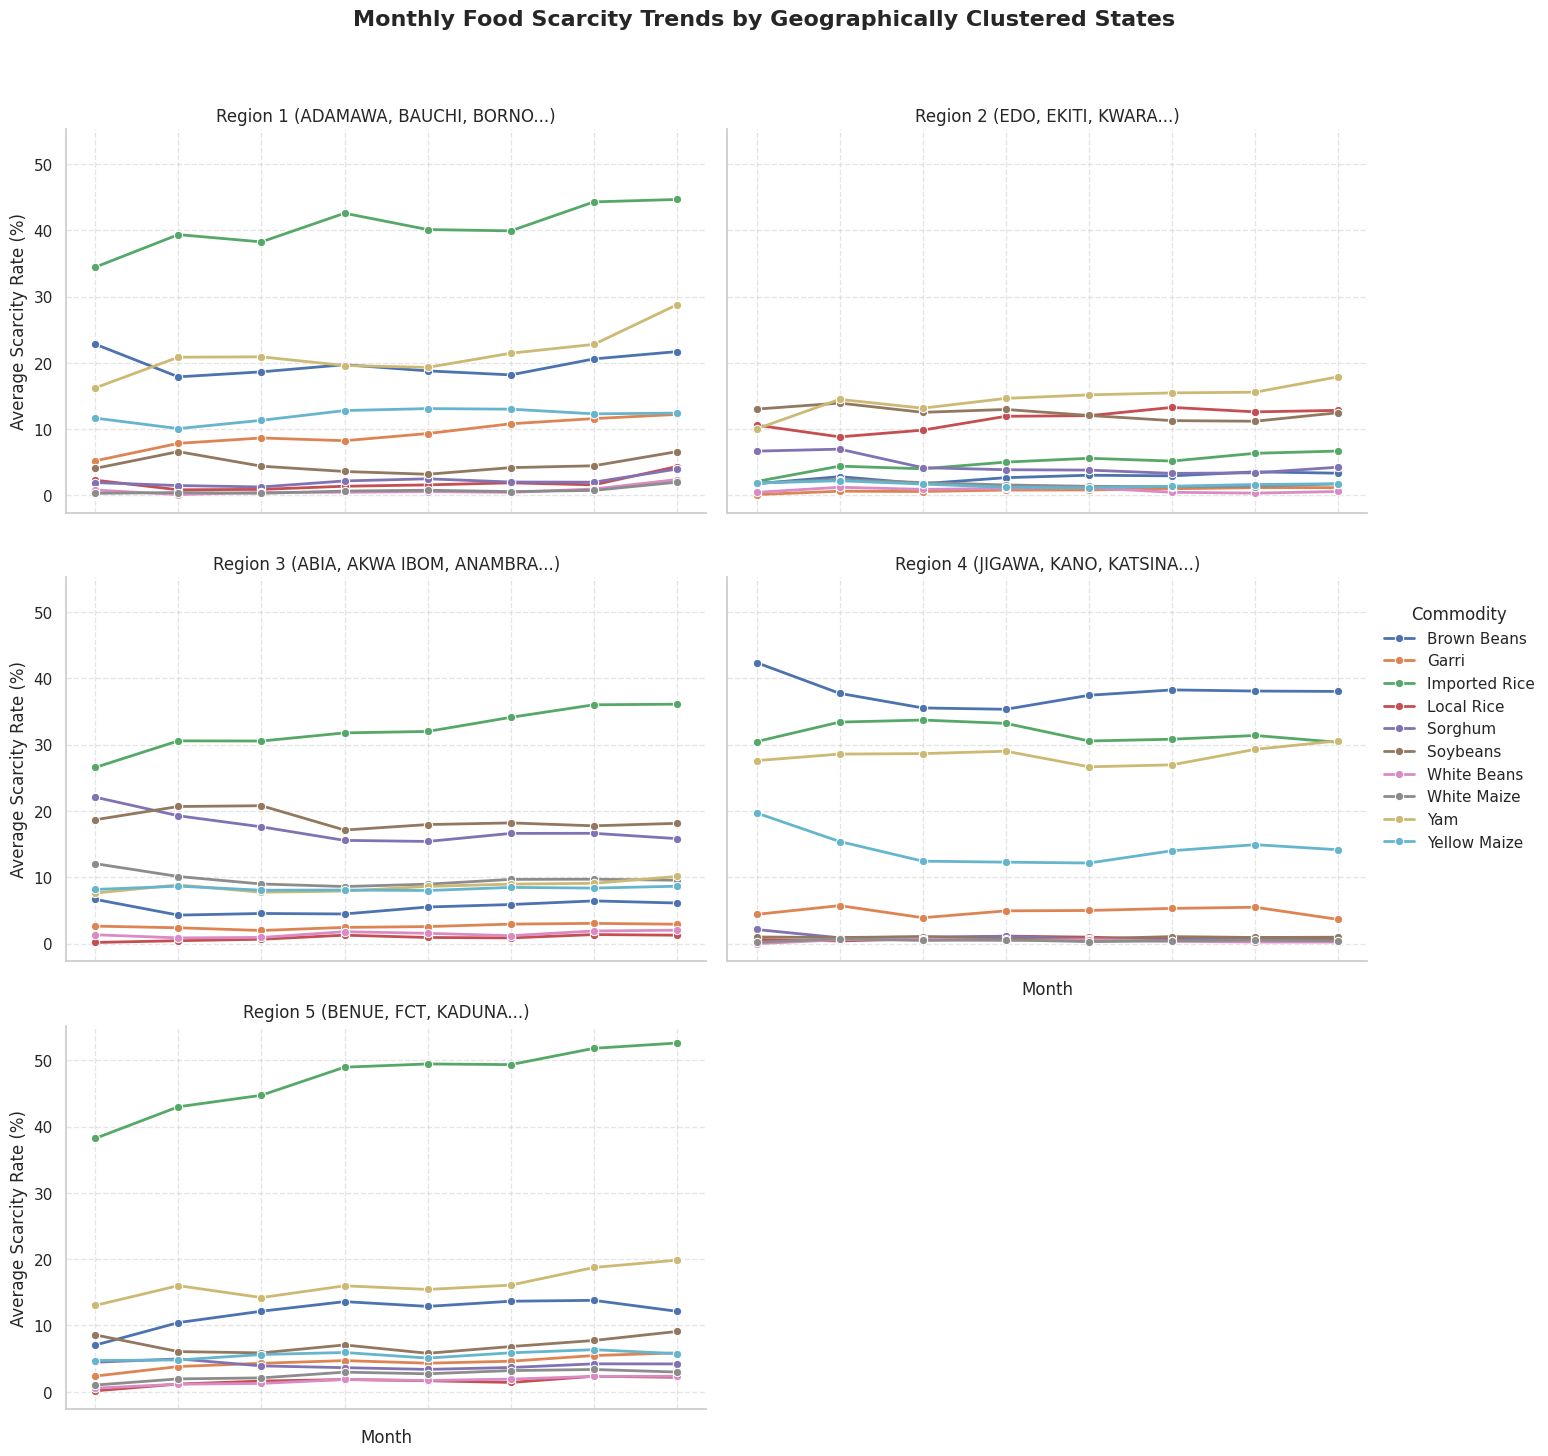

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# Standardize state labels to uppercase to ensure correct matching
df_1['statelabel_upper'] = df_1['statelabel'].astype(str).str.strip().str.upper()
scarcity_df['statelabel_upper'] = scarcity_df['statelabel'].astype(str).str.strip().str.upper()

# 1. Determine average coordinates for each state using df_1
state_coords = df_1.groupby('statelabel_upper')[['gps_latitu', 'gps_longit']].mean().dropna().reset_index()

# Group states into 5 geographic zones using K-Means on their coordinates
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
state_coords['geo_cluster'] = kmeans.fit_predict(state_coords[['gps_latitu', 'gps_longit']])

# Let's give descriptive names to these clusters based on member states
cluster_names = {}
for cluster_id in range(5):
    states_in_cluster = state_coords[state_coords['geo_cluster'] == cluster_id]['statelabel_upper'].tolist()
    representative_states = ", ".join(states_in_cluster[:3])
    cluster_names[cluster_id] = f"Region {cluster_id + 1} ({representative_states}...)"

state_coords['region_name'] = state_coords['geo_cluster'].map(cluster_names)

# 2. Merge region mapping back to our scarcity data
scarcity_geo = pd.merge(
    scarcity_df,
    state_coords[['statelabel_upper', 'region_name']],
    on='statelabel_upper',
    how='inner'
)

# 3. Calculate mean scarcity rate (missing_rate) grouped by Region, Month, and Commodity
regional_scarcity = scarcity_geo.groupby(
    ['region_name', 'year_month_str', 'commodity']
)['missing_rate'].mean().reset_index()

# 4. Plot the results
g = sns.FacetGrid(
    regional_scarcity,
    col='region_name',
    hue='commodity',
    col_wrap=2,
    height=5,
    aspect=1.4,
    sharey=True
)

g.map_dataframe(
    sns.lineplot,
    x='year_month_str',
    y='missing_rate',
    marker='o',
    linewidth=2
)

g.set_axis_labels("Month", "Average Scarcity Rate (%)")
g.set_titles("{col_name}")

for ax in g.axes.flat:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    ax.grid(True, linestyle='--', alpha=0.5)

g.add_legend(title="Commodity")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Monthly Food Scarcity Trends by Geographically Clustered States", fontsize=16, fontweight='bold')
plt.show()

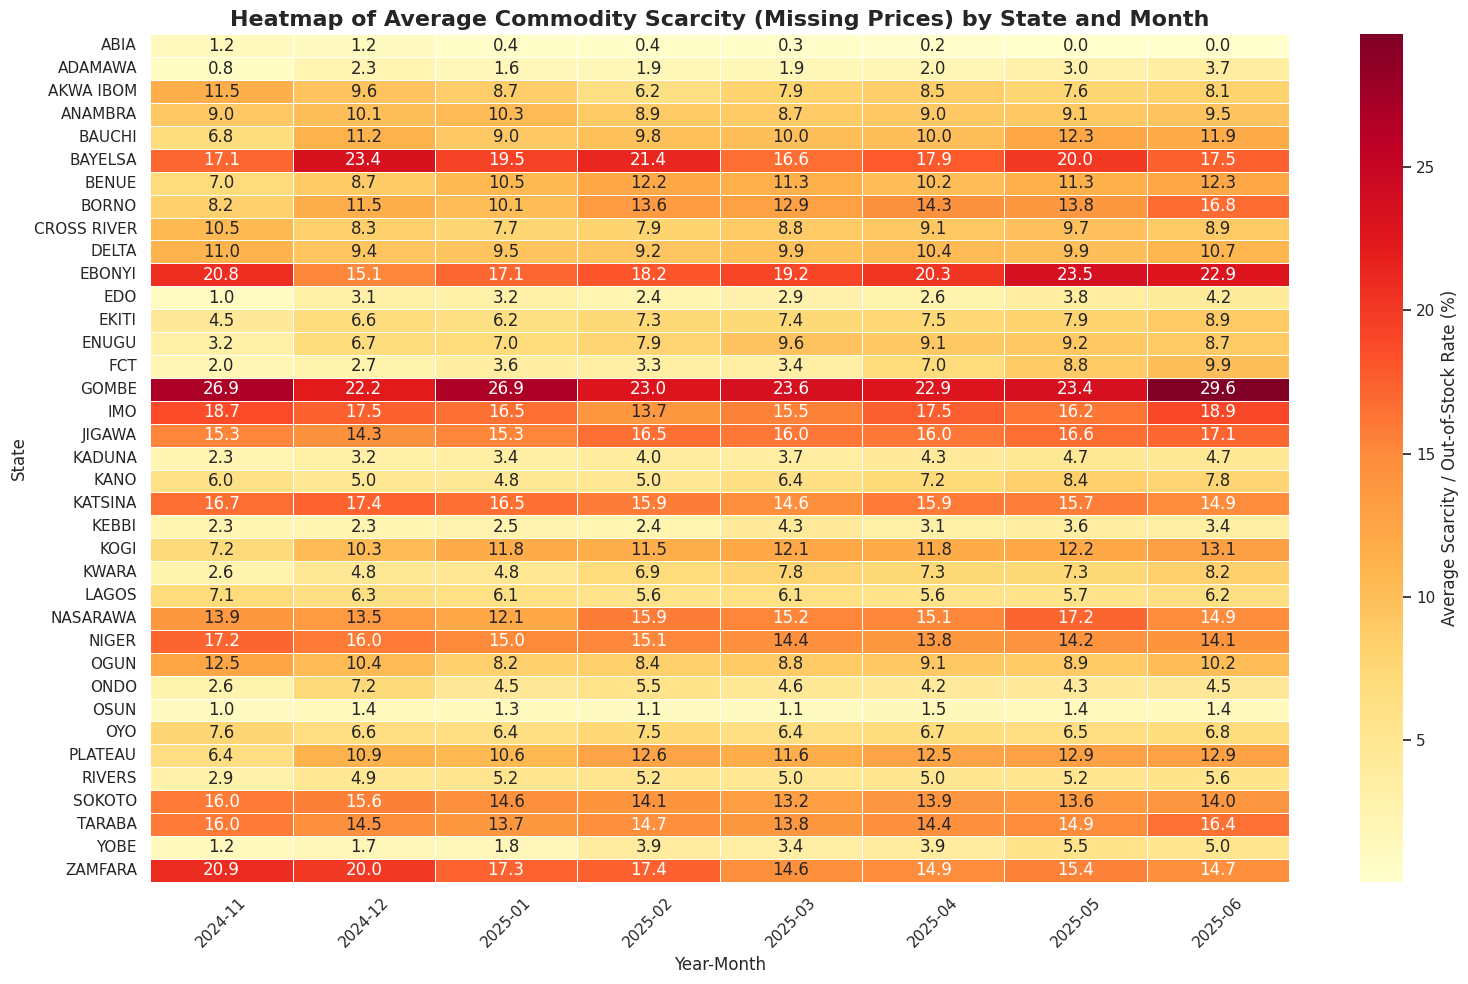

In [16]:
# Calculate overall commodity scarcity by state and time to detect global trends
# Pivot to create a State-Month matrix showing the average missing rate across all commodities
pivot_df = scarcity_df.pivot_table(
    index='statelabel',
    columns='year_month_str',
    values='missing_rate',
    aggfunc='mean'
)

plt.figure(figsize=(16, 10))
sns.heatmap(
    pivot_df,
    cmap='YlOrRd',
    annot=True,
    fmt=".1f",
    linewidths=.5,
    cbar_kws={'label': 'Average Scarcity / Out-of-Stock Rate (%)'}
)

plt.title('Heatmap of Average Commodity Scarcity (Missing Prices) by State and Month', fontsize=16, fontweight='bold')
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('State', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


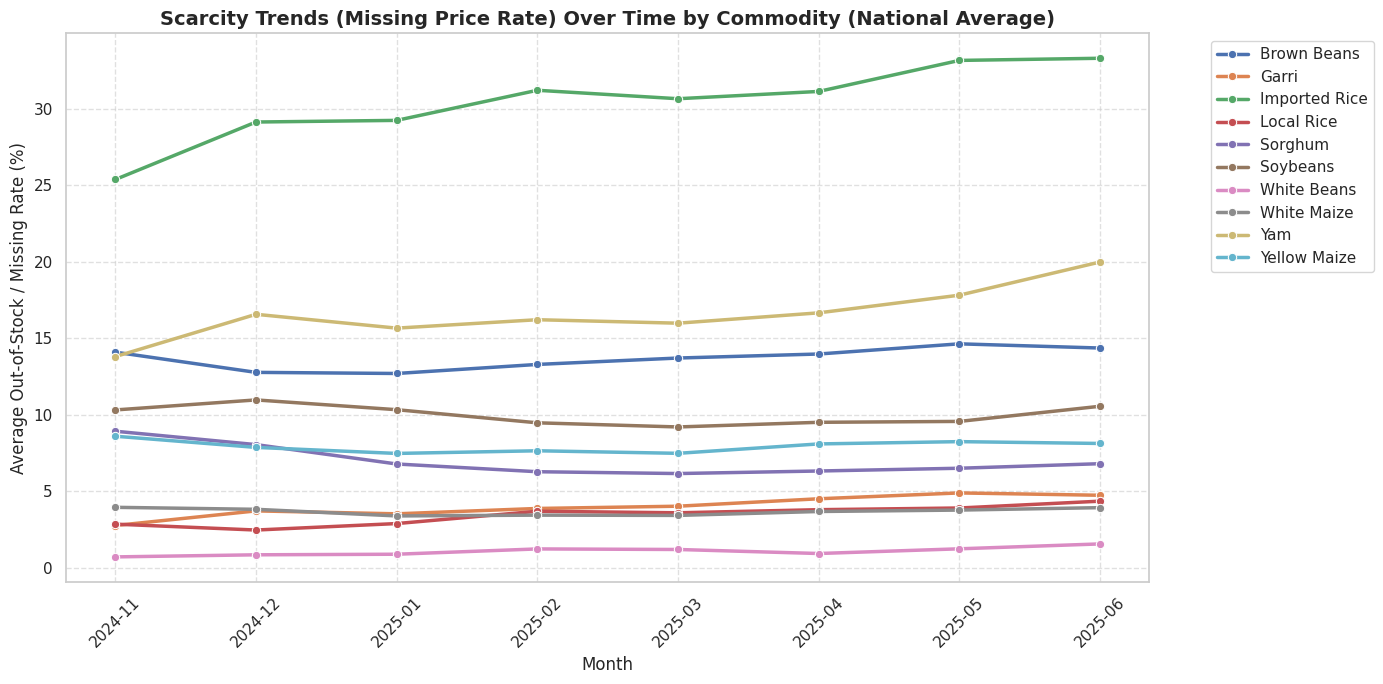

In [17]:
# Detailed view: Let's plot seasonal scarcity trends aggregated across all states for each individual commodity
plt.figure(figsize=(14, 7))
commodity_trends = scarcity_df.groupby(['year_month_str', 'commodity'])['missing_rate'].mean().reset_index()

sns.lineplot(
    data=commodity_trends,
    x='year_month_str',
    y='missing_rate',
    hue='commodity',
    marker='o',
    linewidth=2.5
)

plt.title('Scarcity Trends (Missing Price Rate) Over Time by Commodity (National Average)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Out-of-Stock / Missing Rate (%)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [18]:
# Clean df_1 according to the specified steps
cols_to_drop = [
    'vc_id', 'gps_coords', 'consent', 'staff_vali', 'submissio',
    'lga', 'statecode1', 'zonecode1', 'geopol_zon', 'date_parsed',
    'price_ymai', 'price_wmai', 'price_sorg', 'price_impo', 'price_loca',
    'price_brow', 'price_whit', 'price_garr', 'price_yam', 'price_soya', 'gps_precision'
]

# Identify columns matching prefixes 'uom' and 'q'
uom_q_cols = [col for col in df_1.columns if col.startswith('uom_') or col.startswith('q_')]

# Combine all columns to drop that exist in the dataframe
final_drop_list = [col for col in (cols_to_drop + uom_q_cols) if col in df_1.columns]

df_1_cleaned = df_1.drop(columns=final_drop_list)

print(f"Original shape: {df_1.shape}")
print(f"Cleaned shape: {df_1_cleaned.shape}")
print("\nRemaining columns:")
print(df_1_cleaned.columns.tolist())


Original shape: (220214, 75)
Cleaned shape: (220214, 35)

Remaining columns:
['fid', 'date', 'zonelabel1', 'statelabel', 'lgalabel', 'sector', 'market_typ', 'price_cate', 'market_tim', 'maize_yell', 'price_ym_1', 'maize_whit', 'price_wm_1', 'sorghum', 'price_so_1', 'imported_r', 'price_impo_1', 'local_rice', 'price_lo_1', 'brown_bean', 'price_br_1', 'white_bean', 'price_wh_1', 'garri_conf', 'price_ga_1', 'yam_confir', 'price_yam_', 'soyabeans', 'price_so_2', 'gps_latitu', 'gps_longit', 'gps_precis', 'count', 'year_month', 'statelabel_upper']


### Inspecting Unique Values of Categorical Columns
We will retrieve all columns of type `object` (categorical) in `df_1_cleaned` and display their unique values along with their count to identify any inconsistencies.

In [19]:
# Select categorical (object) columns from df_1_cleaned
categorical_cols = df_1_cleaned.select_dtypes(include=['object']).columns.tolist()

print(f"Found {len(categorical_cols)} categorical columns: {categorical_cols}\n")

# Loop through each and show unique values
for col in categorical_cols:
    unique_vals = df_1_cleaned[col].dropna().unique()
    num_unique = len(unique_vals)
    print(f"=== Column: {col} ({num_unique} unique values) ===")
    if num_unique <= 30:
        print(sorted(list(unique_vals)))
    else:
        print(f"First 20 unique values: {sorted(list(unique_vals))[:20]}...")
    print("\n")

Found 18 categorical columns: ['date', 'zonelabel1', 'statelabel', 'lgalabel', 'sector', 'market_typ', 'price_cate', 'maize_yell', 'maize_whit', 'sorghum', 'imported_r', 'local_rice', 'brown_bean', 'white_bean', 'garri_conf', 'yam_confir', 'soyabeans', 'statelabel_upper']

=== Column: date (217 unique values) ===
First 20 unique values: ['1/1/2025', '1/10/2025', '1/11/2025', '1/12/2025', '1/13/2025', '1/14/2025', '1/15/2025', '1/16/2025', '1/17/2025', '1/18/2025', '1/19/2025', '1/2/2025', '1/20/2025', '1/21/2025', '1/22/2025', '1/23/2025', '1/24/2025', '1/25/2025', '1/26/2025', '1/27/2025']...


=== Column: zonelabel1 (6 unique values) ===
['North Central', 'North East', 'North West', 'South East', 'South South', 'South West']


=== Column: statelabel (37 unique values) ===
First 20 unique values: ['ABIA', 'ADAMAWA', 'AKWA IBOM', 'ANAMBRA', 'BAUCHI', 'BAYELSA', 'BENUE', 'BORNO', 'CROSS RIVER', 'DELTA', 'EBONYI', 'EDO', 'EKITI', 'ENUGU', 'FCT', 'GOMBE', 'IMO', 'JIGAWA', 'KADUNA', 'KANO'

In [20]:
import numpy as np

# Replace whitespace-only strings with NaN across the cleaned dataframe
df_1_cleaned = df_1_cleaned.replace(r'^\s*$', np.nan, regex=True)

# Convert date column to proper datetime
df_1_cleaned['date'] = pd.to_datetime(df_1_cleaned['date'], errors='coerce')

# Verify the cleaning results
print("Categorical Columns Value Counts after Replacing Spaces with NaN:")
for col in ['market_typ', 'price_cate', 'maize_yell', 'maize_whit', 'sorghum']:
    print(f"\nValue counts for {col}:")
    display(df_1_cleaned[col].value_counts(dropna=False))


Categorical Columns Value Counts after Replacing Spaces with NaN:

Value counts for market_typ:


,count
market_typ,
RoadSide_shops_street vendors,67792
Open air_or_covered market,56440
Neighborhood_shops_kiosk,45525
Local_village_market,17574
City_market,14939
Supermarket,6751
Directly_from_Farmer,4169
Bulk_and_discount stores,3556
Specialized_stores,3414



Value counts for price_cate:


,count
price_cate,
Retail,193398
Wholesale,21413
Farmgate,5349
NaN,54



Value counts for maize_yell:


,count
maize_yell,
Yes,203418
No,16741
NaN,55



Value counts for maize_whit:


,count
maize_whit,
Yes,212848
No,7311
NaN,55



Value counts for sorghum:


,count
sorghum,
Yes,206507
No,13652
NaN,55


In [21]:
# 1. Normalize Column Names for the cleaned dataset
df_1_cleaned.columns = df_1_cleaned.columns.str.strip().str.lower().str.replace(' ', '_')

# 2. Normalize Text/String Values in Object Columns
for col in df_1_cleaned.select_dtypes(include=['object']).columns:
    df_1_cleaned[col] = df_1_cleaned[col].astype(str).str.strip().str.lower().str.replace(' ', '_')

# Display the standardized column list and top rows to verify changes
print("Standardized Columns:", df_1_cleaned.columns.tolist())
display(df_1_cleaned.head())

Standardized Columns: ['fid', 'date', 'zonelabel1', 'statelabel', 'lgalabel', 'sector', 'market_typ', 'price_cate', 'market_tim', 'maize_yell', 'price_ym_1', 'maize_whit', 'price_wm_1', 'sorghum', 'price_so_1', 'imported_r', 'price_impo_1', 'local_rice', 'price_lo_1', 'brown_bean', 'price_br_1', 'white_bean', 'price_wh_1', 'garri_conf', 'price_ga_1', 'yam_confir', 'price_yam_', 'soyabeans', 'price_so_2', 'gps_latitu', 'gps_longit', 'gps_precis', 'count', 'year_month', 'statelabel_upper']


,fid,date,zonelabel1,statelabel,lgalabel,sector,market_typ,price_cate,market_tim,maize_yell,...,yam_confir,price_yam_,soyabeans,price_so_2,gps_latitu,gps_longit,gps_precis,count,year_month,statelabel_upper
0,0,2024-12-01,north_central,nasarawa,karu,rural,city_market,retail,10,yes,...,yes,1700.000000,yes,642.857143,9.026682,7.607355,NaN,1,2024-12,nasarawa
1,1,2024-12-01,north_central,nasarawa,karu,rural,local_village_market,retail,15,yes,...,yes,1300.000000,yes,642.857143,9.026682,7.607355,NaN,1,2024-12,nasarawa
2,2,2024-12-02,north_west,kaduna,chikun,urban,open_air_or_covered_market,retail,20,yes,...,yes,2166.666667,yes,1071.428571,10.460725,7.447264,NaN,1,2024-12,kaduna
3,3,2024-12-02,north_central,benue,otukpo,urban,local_village_market,retail,15,yes,...,yes,666.666667,yes,1406.250000,7.192808,8.146351,NaN,1,2024-12,benue
4,4,2024-12-02,north_central,benue,otukpo,urban,neighborhood_shops_kiosk,retail,10,yes,...,yes,500.000000,yes,1562.500000,7.192811,8.146316,NaN,1,2024-12,benue


In [22]:
df_1_cleaned.head().T

,0,1,2,3,4
fid,0,1,2,3,4
date,2024-12-01 00:00:00,2024-12-01 00:00:00,2024-12-02 00:00:00,2024-12-02 00:00:00,2024-12-02 00:00:00
zonelabel1,north_central,north_central,north_west,north_central,north_central
statelabel,nasarawa,nasarawa,kaduna,benue,benue
lgalabel,karu,karu,chikun,otukpo,otukpo
sector,rural,rural,urban,urban,urban
market_typ,city_market,local_village_market,open_air_or_covered_market,local_village_market,neighborhood_shops_kiosk
price_cate,retail,retail,retail,retail,retail
market_tim,10,15,20,15,10
maize_yell,yes,yes,yes,yes,yes


### Melting df_1_cleaned into a Long Format
We will restructure the dataset so that commodity-specific columns are transformed into clean rows with a uniform schema.

In [23]:
import pandas as pd

# Define the identifier columns we want to retain
id_cols = [
    'fid', 'date', 'zonelabel1', 'statelabel', 'lgalabel', 'sector',
    'market_typ', 'price_cate', 'market_tim', 'gps_latitu', 'gps_longit',
    'count', 'year_month'
]

# Map commodities to status columns and standardized price columns
commodity_mapping = {
    'yellow_maize': {'availability': 'maize_yell', 'price': 'price_ym_1'},
    'white_maize': {'availability': 'maize_whit', 'price': 'price_wm_1'},
    'sorghum': {'availability': 'sorghum', 'price': 'price_so_1'},
    'imported_rice': {'availability': 'imported_r', 'price': 'price_impo_1'},
    'local_rice': {'availability': 'local_rice', 'price': 'price_lo_1'},
    'brown_beans': {'availability': 'brown_bean', 'price': 'price_br_1'},
    'white_beans': {'availability': 'white_bean', 'price': 'price_wh_1'},
    'garri': {'availability': 'garri_conf', 'price': 'price_ga_1'},
    'yam': {'availability': 'yam_confir', 'price': 'price_yam_'},
    'soybeans': {'availability': 'soyabeans', 'price': 'price_so_2'}
}

# Extract lists of columns for availability and prices
avail_cols = [v['availability'] for v in commodity_mapping.values()]
price_cols = [v['price'] for v in commodity_mapping.values()]

# 1. Melt availability columns
df_avail_melted = pd.melt(
    df_1_cleaned,
    id_vars=id_cols,
    value_vars=avail_cols,
    var_name='availability_col',
    value_name='is_available'
)

# Create a standard commodity column name to match on
reverse_avail_map = {v['availability']: k for k, v in commodity_mapping.items()}
df_avail_melted['commodity'] = df_avail_melted['availability_col'].map(reverse_avail_map)
df_avail_melted.drop(columns=['availability_col'], inplace=True)

# 2. Melt price columns
df_price_melted = pd.melt(
    df_1_cleaned,
    id_vars=id_cols,
    value_vars=price_cols,
    var_name='price_col',
    value_name='standardized_price'
)

# Create a standard commodity column name to match on
reverse_price_map = {v['price']: k for k, v in commodity_mapping.items()}
df_price_melted['commodity'] = df_price_melted['price_col'].map(reverse_price_map)
df_price_melted.drop(columns=['price_col'], inplace=True)

# 3. Merge availability and price melted dataframes
df_melted = pd.merge(
    df_avail_melted,
    df_price_melted,
    on=id_cols + ['commodity'],
    how='inner'
)

print(f"Melted Long Dataframe Shape: {df_melted.shape}")
display(df_melted.head())


Melted Long Dataframe Shape: (2202140, 16)


,fid,date,zonelabel1,statelabel,lgalabel,sector,market_typ,price_cate,market_tim,gps_latitu,gps_longit,count,year_month,is_available,commodity,standardized_price
0,0,2024-12-01,north_central,nasarawa,karu,rural,city_market,retail,10,9.026682,7.607355,1,2024-12,yes,yellow_maize,807.692308
1,1,2024-12-01,north_central,nasarawa,karu,rural,local_village_market,retail,15,9.026682,7.607355,1,2024-12,yes,yellow_maize,846.153846
2,2,2024-12-02,north_west,kaduna,chikun,urban,open_air_or_covered_market,retail,20,10.460725,7.447264,1,2024-12,yes,yellow_maize,1000.000000
3,3,2024-12-02,north_central,benue,otukpo,urban,local_village_market,retail,15,7.192808,8.146351,1,2024-12,yes,yellow_maize,1321.428571
4,4,2024-12-02,north_central,benue,otukpo,urban,neighborhood_shops_kiosk,retail,10,7.192811,8.146316,1,2024-12,yes,yellow_maize,500.000000


In [24]:
df_melted.nunique()

,0
fid,220214
date,217
zonelabel1,6
statelabel,37
lgalabel,591
sector,2
market_typ,10
price_cate,4
market_tim,374
gps_latitu,210196


In [25]:
negative_times = (df_melted['market_tim'] < 0).sum()
extreme_times = (df_melted['market_tim'] > 480).sum()  # over 8 hours
print(f"Submissions with negative market travel times: {negative_times}")
print(f"Submissions with > 8 hours travel time: {extreme_times}")

Submissions with negative market travel times: 160
Submissions with > 8 hours travel time: 2210


**DATA CHANGING**

In [26]:
# 1. Map 'is_available' to binary (True NaNs remain NaN, representing unrecorded/skipped checks)
df_melted["is_available"] = df_melted["is_available"].astype(str).str.strip().str.lower().map(
    {"yes": 1, "no": 0,"Yes": 1, "No": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0}
)

In [27]:
import pandas as pd

# 1. Convert year_month to timestamp if it is a Period, then extract year/month
if isinstance(df_melted['year_month'].dtype, pd.PeriodDtype):
    df_melted['year_month'] = df_melted['year_month'].dt.to_timestamp()
else:
    df_melted['year_month'] = pd.to_datetime(df_melted['year_month'], errors='coerce')

# 2. Extract year and month
df_melted['year'] = df_melted['year_month'].dt.year
df_melted['month'] = df_melted['year_month'].dt.month

# 3. Double check the values to ensure there are no NaNs anymore
print("Null counts:")
print(df_melted[['year_month', 'year', 'month']].isnull().sum())
print("\nFirst few rows:")
display(df_melted[['year_month', 'year', 'month']].head())

Null counts:
year_month    0
year          0
month         0
dtype: int64

First few rows:


,year_month,year,month
0,2024-12-01,2024,12
1,2024-12-01,2024,12
2,2024-12-01,2024,12
3,2024-12-01,2024,12
4,2024-12-01,2024,12


In [ ]:
# Calculate the 75th percentile (Q3) for standardized_price
q3_value = df_melted['standardized_price'].quantile(0.75)

# Count how many non-null values are strictly above Q3
values_above_q3 = df_melted[df_melted['standardized_price'] > q3_value]
count_above_q3 = len(values_above_q3)

print(f"The 75th percentile (Q3) of standardized_price is: {q3_value:.2f}")
print(f"Number of price entries above this threshold: {count_above_q3:,} (out of {df_melted['standardized_price'].notnull().sum():,} total recorded prices)")

The 75th percentile (Q3) of standardized_price is: 2000.00
Number of price entries above this threshold: 492,810 (out of 1,994,779 total recorded prices)


In [28]:
# Remove standardized_price outliers

# Calculate outlier threshold (e.g., 99.9th percentile)
price_threshold = df_melted['standardized_price'].quantile(0.999)

# Remove rows above the threshold
df_melted = df_melted[
    df_melted['standardized_price'] <= price_threshold
].copy()

print(f"Threshold: {price_threshold:.2f}")
print(f"New dataset shape: {df_melted.shape}")

Threshold: 20000.00
New dataset shape: (1992872, 18)


In [29]:
df_melted.head()

,fid,date,zonelabel1,statelabel,lgalabel,sector,market_typ,price_cate,market_tim,gps_latitu,gps_longit,count,year_month,is_available,commodity,standardized_price,year,month
0,0,2024-12-01,north_central,nasarawa,karu,rural,city_market,retail,10,9.026682,7.607355,1,2024-12-01,1.0,yellow_maize,807.692308,2024,12
1,1,2024-12-01,north_central,nasarawa,karu,rural,local_village_market,retail,15,9.026682,7.607355,1,2024-12-01,1.0,yellow_maize,846.153846,2024,12
2,2,2024-12-02,north_west,kaduna,chikun,urban,open_air_or_covered_market,retail,20,10.460725,7.447264,1,2024-12-01,1.0,yellow_maize,1000.000000,2024,12
3,3,2024-12-02,north_central,benue,otukpo,urban,local_village_market,retail,15,7.192808,8.146351,1,2024-12-01,1.0,yellow_maize,1321.428571,2024,12
4,4,2024-12-02,north_central,benue,otukpo,urban,neighborhood_shops_kiosk,retail,10,7.192811,8.146316,1,2024-12-01,1.0,yellow_maize,500.000000,2024,12


CREATE LAGGING TIME HISTORY

In [30]:
group_cols = [
    'commodity',
    'statelabel',
    'lgalabel',
    'gps_latitu',
    'gps_longit',
]

In [31]:
df_melted = df_melted.sort_values(
    group_cols + ['date']
).copy()

In [32]:
df_melted['price_lag_1'] = (
    df_melted.groupby(group_cols)['standardized_price']
    .shift(1)
)

df_melted['price_lag_7'] = (
    df_melted.groupby(group_cols)['standardized_price']
    .shift(7)
)


In [ ]:
df_melted['rolling_mean_7'] = (
    df_melted.groupby(group_cols)['standardized_price']
    .transform(
        lambda x: x.shift(1).rolling(7).mean()
    )
)

df_melted['rolling_std_7'] = (
    df_melted.groupby(group_cols)['standardized_price']
    .transform(
        lambda x: x.shift(1).rolling(7).std()
    )
)

In [ ]:
df_melted['price_change_7'] = (
    df_melted.groupby(group_cols)['standardized_price']
    .transform(lambda x: x.shift(1) / x.shift(8) - 1)
)

In [ ]:
# Create a copy containing the future prices
future_prices = df_melted[
    group_cols + ['Date', 'standardized_price']
].copy()

def create_target(data, horizon):

    future = future_prices.copy()

    future['date'] = (
        future['date'] -
        pd.Timedelta(days=horizon)
    )

    future = future.rename(
        columns={
            'standardized_price': f'target_{horizon}d'
        }
    )

    result = data.merge(
        future,
        on=group_cols + ['date'],
        how='left',
        validate='many_to_one'
    )

    return result


df_1d = create_target(df_melted, 1)
df_7d = create_target(df_melted, 7)
df_30d = create_target(df_melted, 30)

commodity: category

market_type: ordinal

zonelabel: category

statelabel: category under zone label

lgalabel: category under statelabel

sector: category

In [ ]:
# Define columns we want to explicitly exclude from features for predicting price
exclude_cols_linear = [
    "fid",
    "date",
    "zonelabel1",
    "statelabel",
    "lgalabel",
    "gps_precis",
    "year_month",
    "market_typ",
    "price_cate",
    "commodity",
    "sector",
    "standardized_price"  # Must exclude target from features!
    "market_time"
]

# Dynamically build feature list from df_melted columns
stockout_features_linear = [col for col in df_melted.columns if col not in exclude_cols_linear]

print("Features to be used for Linear Regression training:")
print(stockout_features_linear)

# Define X and y using updated feature set
X_linear = df_melted[stockout_features_linear]
y_linear = df_melted["standardized_price"]

Features to be used for Linear Regression training:
['market_tim', 'gps_latitu', 'gps_longit', 'count', 'is_available', 'year', 'month', 'statelabel_encoded', 'lgalabel_encoded', 'sector_encoded', 'market_typ_encoded', 'price_cate_encoded', 'commodity_encoded']


In [ ]:
# 2. Encode categorical columns.

import pandas as pd
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# 1. Copy datasets
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

# 2. Define categorical columns
categorical_cols = [
    'commodity',
    'zonelabel1',
    'sector'
]

# 3. Define ordinal column
ordinal_cols = ['market_typ']

# 4. Hierarchical encoding
def create_hierarchy(df):
    df = df.copy()

    # State belongs to a zone
    df['zone_state'] = (
        df['zonelabel1'].astype(str) + '__' +
        df['statelabel'].astype(str)
    )

    # LGA belongs to a state
    df['state_lga'] = (
        df['statelabel'].astype(str) + '__' +
        df['lgalabel'].astype(str)
    )

    return df


X_train = create_hierarchy(X_train)
X_val = create_hierarchy(X_val)
X_test = create_hierarchy(X_test)

# 5. Add hierarchical columns to categorical encoding
categorical_cols += ['zone_state', 'state_lga']

# 6. One-Hot Encoding
onehot_encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

X_train_cat = onehot_encoder.fit_transform(
    X_train[categorical_cols]
)

X_val_cat = onehot_encoder.transform(
    X_val[categorical_cols]
)

X_test_cat = onehot_encoder.transform(
    X_test[categorical_cols]
)

# 7. Ordinal Encoding
ordinal_encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train_ord = ordinal_encoder.fit_transform(
    X_train[ordinal_cols]
)

X_val_ord = ordinal_encoder.transform(
    X_val[ordinal_cols]
)

X_test_ord = ordinal_encoder.transform(
    X_test[ordinal_cols]
)

# 8. Convert encoded arrays to DataFrames
cat_feature_names = onehot_encoder.get_feature_names_out(
    categorical_cols
)

ord_feature_names = ordinal_cols

X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=cat_feature_names,
    index=X_train.index
)

X_val_cat = pd.DataFrame(
    X_val_cat,
    columns=cat_feature_names,
    index=X_val.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=cat_feature_names,
    index=X_test.index
)

X_train_ord = pd.DataFrame(
    X_train_ord,
    columns=ord_feature_names,
    index=X_train.index
)

X_val_ord = pd.DataFrame(
    X_val_ord,
    columns=ord_feature_names,
    index=X_val.index
)

X_test_ord = pd.DataFrame(
    X_test_ord,
    columns=ord_feature_names,
    index=X_test.index
)

# 9. Combine encoded features
X_train_encoded = pd.concat(
    [X_train_cat, X_train_ord],
    axis=1
)

X_val_encoded = pd.concat(
    [X_val_cat, X_val_ord],
    axis=1
)

X_test_encoded = pd.concat(
    [X_test_cat, X_test_ord],
    axis=1
)

# 10. Inspect results
print("Training shape:", X_train_encoded.shape)
print("Validation shape:", X_val_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

display(X_train_encoded.head())


In [ ]:
df_melted.head().T

,0,1,2,3,4
fid,0,1,2,3,4
date,2024-12-01 00:00:00,2024-12-01 00:00:00,2024-12-02 00:00:00,2024-12-02 00:00:00,2024-12-02 00:00:00
zonelabel1,North Central,North Central,North West,North Central,North Central
statelabel,NASARAWA,NASARAWA,KADUNA,BENUE,BENUE
lgalabel,KARU,KARU,CHIKUN,OTUKPO,OTUKPO
sector,Rural,Rural,Urban,Urban,Urban
market_typ,City_market,Local_village_market,Open air_or_covered market,Local_village_market,Neighborhood_shops_kiosk
price_cate,Retail,Retail,Retail,Retail,Retail
market_tim,10,15,20,15,10
gps_latitu,9.026682,9.026682,10.460725,7.192808,7.192811


In [ ]:
# Check for NaN values

In [ ]:
df_melted.head()

,fid,date,zonelabel1,statelabel,lgalabel,sector,market_typ,price_cate,market_tim,gps_latitu,...,commodity,standardized_price,statelabel_encoded,lgalabel_encoded,sector_encoded,market_typ_encoded,price_cate_encoded,commodity_encoded,year,month
0,0,2024-12-01,north_central,nasarawa,karu,rural,city_market,retail,10,9.026682,...,yellow_maize,807.692308,25,333,0,1,2,9,2024,12
1,1,2024-12-01,north_central,nasarawa,karu,rural,local_village_market,retail,15,9.026682,...,yellow_maize,846.153846,25,333,0,3,2,9,2024,12
2,2,2024-12-02,north_west,kaduna,chikun,urban,open_air_or_covered_market,retail,20,10.460725,...,yellow_maize,1000.000000,18,109,1,6,2,9,2024,12
3,3,2024-12-02,north_central,benue,otukpo,urban,local_village_market,retail,15,7.192808,...,yellow_maize,1321.428571,6,484,1,3,2,9,2024,12
4,4,2024-12-02,north_central,benue,otukpo,urban,neighborhood_shops_kiosk,retail,10,7.192811,...,yellow_maize,500.000000,6,484,1,5,2,9,2024,12


In [ ]:
X_train_linear.head()

,market_tim,gps_latitu,gps_longit,count,is_available,year,month,statelabel_encoded,lgalabel_encoded,sector_encoded,market_typ_encoded,price_cate_encoded,commodity_encoded
0,10,9.026682,7.607355,1,1.0,2024,12,0.030602,0.012583,0.313631,0.067839,0.878228,0.1
1,15,9.026682,7.607355,1,1.0,2024,12,0.030602,0.012583,0.313631,0.079804,0.878228,0.1
2,20,10.460725,7.447264,1,1.0,2024,12,0.033118,0.011076,0.686369,0.256296,0.878228,0.1
3,15,7.192808,8.146351,1,1.0,2024,12,0.025443,0.005908,0.686369,0.079804,0.878228,0.1
4,10,7.192811,8.146316,1,1.0,2024,12,0.025443,0.005908,0.686369,0.206731,0.878228,0.1


In [ ]:
df_melted.describe()

,fid,date,market_tim,gps_latitu,gps_longit,count,year_month,is_available,standardized_price,year,month,statelabel_encoded,lgalabel_encoded,sector_encoded,market_typ_encoded,price_cate_encoded,commodity_encoded
count,2.202140e+06,2202140,2.202140e+06,2.202140e+06,2.202140e+06,2202140.0,2202140,2.201590e+06,1.994779e+06,2.202140e+06,2.202140e+06,2.202140e+06,2.202140e+06,2.202140e+06,2.202140e+06,2.202140e+06,2.202140e+06
mean,1.101065e+05,2025-03-14 22:31:06.453539328,5.980224e+03,8.529373e+00,7.287308e+00,1.0,2025-02-28 05:14:58.896527360,9.060629e-01,2.938530e+03,2.024843e+03,4.822504e+00,2.845641e-02,5.007668e-03,5.694666e-01,2.159646e-01,7.813288e-01,1.000000e-01
min,0.000000e+00,2024-11-26 00:00:00,-8.500000e+01,4.426009e+00,2.714769e+00,1.0,2024-11-01 00:00:00,0.000000e+00,0.000000e+00,2.024000e+03,1.000000e+00,1.454948e-02,4.541037e-06,3.136313e-01,2.452160e-04,2.452160e-04,1.000000e-01
25%,5.505300e+04,2025-01-21 00:00:00,1.000000e+01,6.456500e+00,5.264294e+00,1.0,2025-01-01 00:00:00,1.000000e+00,1.000000e+03,2.025000e+03,2.000000e+00,2.544343e-02,2.043467e-03,3.136313e-01,2.067307e-01,8.782275e-01,1.000000e-01
50%,1.101065e+05,2025-03-15 00:00:00,2.000000e+01,7.843022e+00,7.336395e+00,1.0,2025-03-01 00:00:00,1.000000e+00,1.461538e+03,2.025000e+03,4.000000e+00,2.698284e-02,3.696404e-03,6.863687e-01,2.562961e-01,8.782275e-01,1.000000e-01
75%,1.651600e+05,2025-05-07 00:00:00,4.000000e+01,1.048857e+01,8.529103e+00,1.0,2025-05-01 00:00:00,1.000000e+00,2.000000e+03,2.025000e+03,6.000000e+00,3.080186e-02,7.874159e-03,6.863687e-01,3.078460e-01,8.782275e-01,1.000000e-01
max,2.202130e+05,2025-06-30 00:00:00,6.584807e+08,1.375410e+01,1.420932e+01,1.0,2025-06-01 00:00:00,1.000000e+00,5.737940e+08,2.025000e+03,1.200000e+01,4.498806e-02,1.791439e-02,6.863687e-01,3.078460e-01,8.782275e-01,1.000000e-01
std,6.357032e+04,NaN,1.842413e+06,2.514294e+00,2.430835e+00,0.0,NaN,2.917413e-01,6.866166e+05,3.635369e-01,3.436972e+00,6.540714e-03,3.876597e-03,1.729384e-01,9.522736e-02,2.604259e-01,3.782794e-12


**LINEAR REGRESSION MODELLING TO PREDICT PRICE**

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

# Initialize the baseline regressor to predict the mean value of training prices
baseline = DummyRegressor(strategy='mean')

# Fit the baseline on the training set (log scale)
baseline.fit(X_train_linear, y_train_linear)

# Make baseline predictions
baseline_pred_log = baseline.predict(X_test_linear)

# Convert both the true labels and predictions back to the actual price scale
y_test_actual = np.expm1(y_test_linear)
baseline_pred_actual = np.expm1(baseline_pred_log)

print("Baseline R2 Score:", r2_score(y_test_actual, baseline_pred_actual))
print("Baseline MAE:", mean_absolute_error(y_test_actual, baseline_pred_actual))

Baseline R2 Score: -0.002367996097480951
Baseline MAE: 542.2393469410628


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialize the Linear Regression model
price_predictor = LinearRegression()

# Train the model on log-transformed, outlier-trimmed targets
print("Training Linear Regression model on trimmed, Log-Transformed target variable...")
price_predictor.fit(X_train_linear, y_train_linear)

# Predict in log scale
y_pred_price_log = price_predictor.predict(X_test_linear)

# Convert back to actual prices using expm1 for metrics evaluation
y_test_actual = np.expm1(y_test_linear)
y_pred_actual = np.expm1(y_pred_price_log)

# Evaluate the model's performance on the original price scale
mae = mean_absolute_error(y_test_actual, y_pred_actual)
mse = mean_squared_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_actual, y_pred_actual)

print("\n--- Linear Regression Performance Metrics (After Outlier Trimming & Log-Transformation) ---")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")

Training Linear Regression model on trimmed, Log-Transformed target variable...

--- Linear Regression Performance Metrics (After Outlier Trimming & Log-Transformation) ---
Mean Absolute Error (MAE): 539.5131
Mean Squared Error (MSE): 863280.7396
Root Mean Squared Error (RMSE): 929.1290
R-squared (R2 Score): 0.0335
